# Linear Models from Scratch

Evaluate custom NumPy implementations of **Linear Regression** and **Logistic Regression** against scikit-learn.

- Regression: test MSE on the Diabetes dataset.
- Binary classification: accuracy and log loss on a synthetic dataset.
- Inspect training loss to verify that gradient descent is working.

Model implementations remain in `src/linear_models.py`; loss functions remain in `src/losses.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, log_loss

from src.linear_models import LinearRegression as CustomLinearRegression
from src.linear_models import LogisticRegression as CustomLogisticRegression
from src.losses import mse

## 1. Linear Regression

**Task:** Predict a continuous target on the Diabetes dataset. Standardize features using the training data only.

In [2]:
X_reg, y_reg = load_diabetes(return_X_y=True)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=101
)

reg_scaler = StandardScaler()
X_reg_train = reg_scaler.fit_transform(X_reg_train)
X_reg_test = reg_scaler.transform(X_reg_test)

print(f"Train samples: {X_reg_train.shape[0]}")
print(f"Test samples:  {X_reg_test.shape[0]}")
print(f"Features:      {X_reg_train.shape[1]}")

Train samples: 353
Test samples:  89
Features:      10


### Train and compare

The custom implementation uses gradient descent; scikit-learn's `LinearRegression` solves ordinary least squares directly. Compare their **test MSE**.

In [3]:
linear_model = CustomLinearRegression(n_iterations=1000, lr=0.01)
sklearn_linear = SklearnLinearRegression()

linear_model.fit(X_reg_train, y_reg_train)
sklearn_linear.fit(X_reg_train, y_reg_train)

linear_pred = linear_model.predict(X_reg_test)
sklearn_linear_pred = sklearn_linear.predict(X_reg_test)

linear_results = pd.DataFrame({
    "Model": ["Custom Linear Regression", "sklearn Linear Regression"],
    "Test MSE": [mse(y_reg_test, linear_pred), mse(y_reg_test, sklearn_linear_pred)],
})
linear_results

,Model,Test MSE
0,Custom Linear Regression,2822.298178
1,sklearn Linear Regression,2778.580485


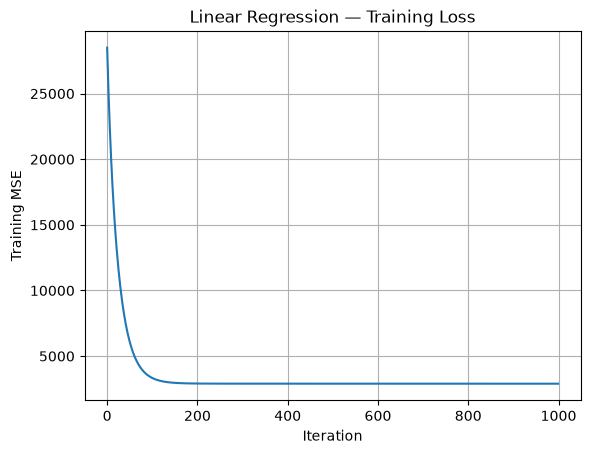

In [4]:
plt.plot(linear_model.losses_history)
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.title("Linear Regression — Training Loss")
plt.grid(True)
plt.show()

### Quick sanity check

For a simple synthetic relationship \(y=3x+12\), the fitted slope and bias should be close to 3 and 12.

In [5]:
X_simple = np.array([[-2], [-1], [0], [1], [2]])
y_simple = 3 * X_simple.ravel() + 12

simple_linear_model = CustomLinearRegression(n_iterations=1000, lr=0.01)
simple_linear_model.fit(X_simple, y_simple)
print("Weights:", simple_linear_model.weights)
print("Bias:", simple_linear_model.bias)

Weights: [3.]
Bias: 11.999999981487356


## 2. Logistic Regression

**Task:** Binary classification on synthetic data with two features.

Custom model: \(z=Xw+b\), \(p=\sigma(z)\). The `predict_proba()` method returns positive-class probabilities; `predict()` applies a threshold of 0.5.

We standardize the training features and apply the same transformation to the test set.

In [6]:
X_clf, y_clf = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.2,
    random_state=42,
)

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, stratify=y_clf, random_state=42
)

clf_scaler = StandardScaler()
X_clf_train = clf_scaler.fit_transform(X_clf_train)
X_clf_test = clf_scaler.transform(X_clf_test)

print(f"Train samples: {X_clf_train.shape[0]}")
print(f"Test samples:  {X_clf_test.shape[0]}")
print(f"Features:      {X_clf_train.shape[1]}")

Train samples: 400
Test samples:  100
Features:      2


### Train and compare

Compare **accuracy** and **binary log loss**. `C=1e6` makes the scikit-learn model approximately unregularized, closer to the custom model (which does not implement L2 regularization). Results need not match exactly because the optimizers differ.

In [7]:
logistic_model = CustomLogisticRegression(n_iterations=2000, lr=0.1)
sklearn_logistic = SklearnLogisticRegression(C=1e6, max_iter=2000)

logistic_model.fit(X_clf_train, y_clf_train)
sklearn_logistic.fit(X_clf_train, y_clf_train)

custom_probs = logistic_model.predict_proba(X_clf_test)
sklearn_probs = sklearn_logistic.predict_proba(X_clf_test)[:, 1]

custom_classes = logistic_model.predict(X_clf_test)
sklearn_classes = sklearn_logistic.predict(X_clf_test)

logistic_results = pd.DataFrame({
    "Model": ["Custom Logistic Regression", "sklearn Logistic Regression"],
    "Test Accuracy": [accuracy_score(y_clf_test, custom_classes),
                      accuracy_score(y_clf_test, sklearn_classes)],
    "Test Log Loss": [log_loss(y_clf_test, custom_probs),
                      log_loss(y_clf_test, sklearn_probs)],
})
logistic_results

,Model,Test Accuracy,Test Log Loss
0,Custom Logistic Regression,0.91,0.207813
1,sklearn Logistic Regression,0.91,0.204859


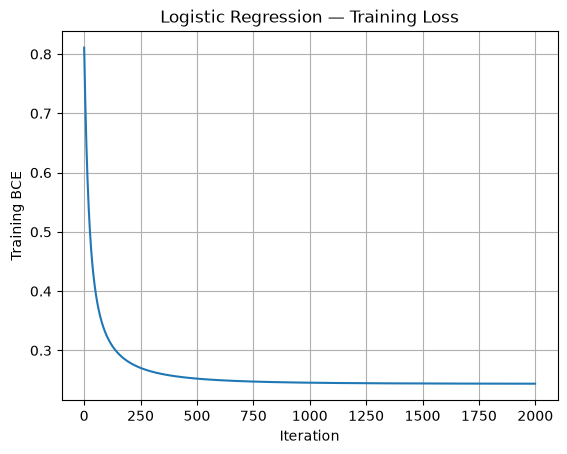

In [8]:
plt.plot(logistic_model.losses_history)
plt.xlabel("Iteration")
plt.ylabel("Training BCE")
plt.title("Logistic Regression — Training Loss")
plt.grid(True)
plt.show()

### Predicted probabilities vs predicted classes

A positive-class probability is **not** a class label. For example, `0.72` becomes class `1` at threshold `0.5`, while `0.31` becomes class `0`.

In [9]:
pd.DataFrame({
    "Actual": y_clf_test[:8],
    "P(class=1)": custom_probs[:8].round(3),
    "Predicted (threshold=0.5)": custom_classes[:8],
})

,Actual,P(class=1),Predicted (threshold=0.5)
0,1,0.847,1
1,0,0.000,0
2,0,0.001,0
3,1,0.811,1
4,1,0.971,1
5,1,0.993,1
6,1,0.866,1
7,0,0.746,1


## 3. Summary

- **Linear Regression:** predicts a continuous value; evaluates with MSE.
- **Logistic Regression:** predicts a probability through the sigmoid; trains with BCE and converts probabilities to classes using a threshold.
- Both custom implementations use gradient descent and should show decreasing training loss.
- Automated checks for model behavior belong in `tests/`, rather than duplicating the whole implementation here.

Run all notebook cells from the repository root after making sure `src/linear_models.py` contains both model classes.